TensorFlow: 2.21.0
GPU Available: True
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4775s 28us/step

Training images: 2000
Image shape: (32, 32, 3)


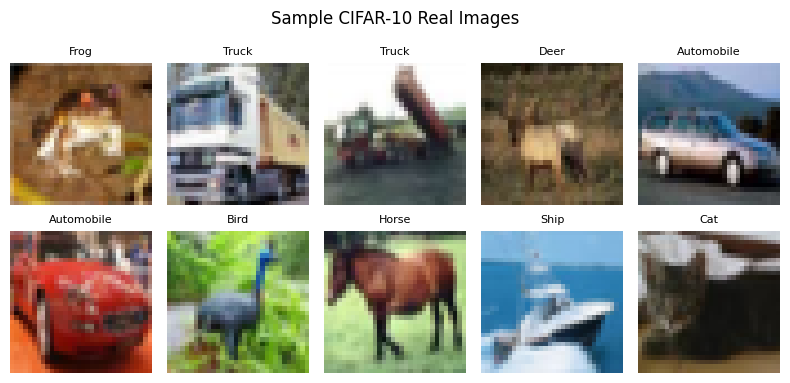

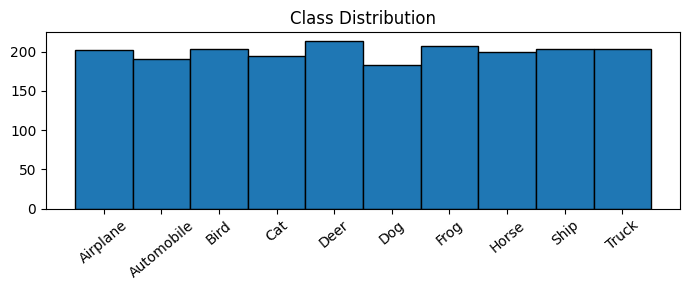

Epoch 1/3 | D Loss: 1.4293 | G Loss: 0.6974
Epoch 2/3 | D Loss: 1.4026 | G Loss: 0.7054
Epoch 3/3 | D Loss: 1.3781 | G Loss: 0.7510


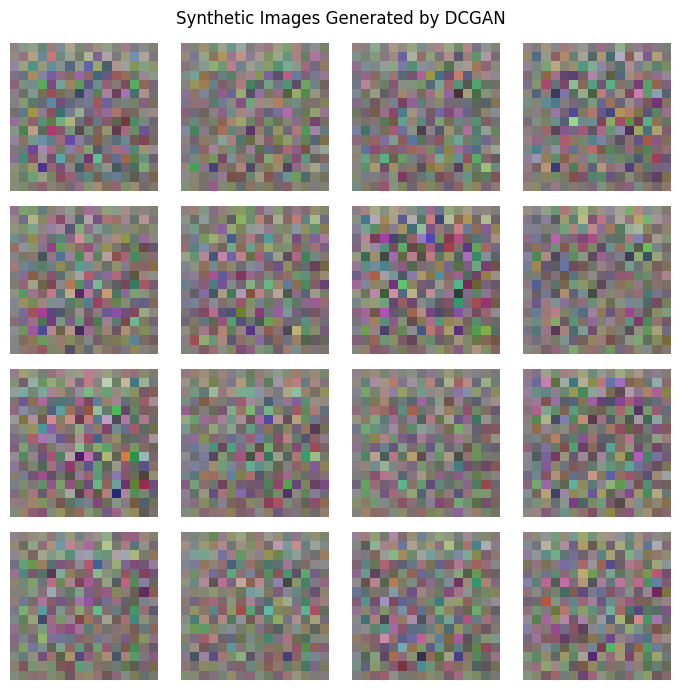

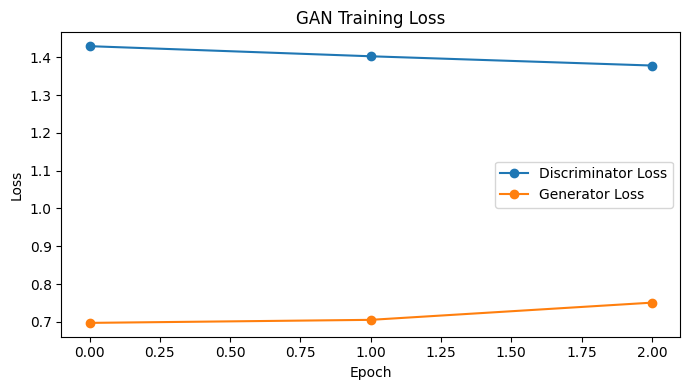


Discriminator Accuracy: 0.685

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake       0.61      1.00      0.76       500
        Real       1.00      0.37      0.54       500

    accuracy                           0.69      1000
   macro avg       0.81      0.69      0.65      1000
weighted avg       0.81      0.69      0.65      1000



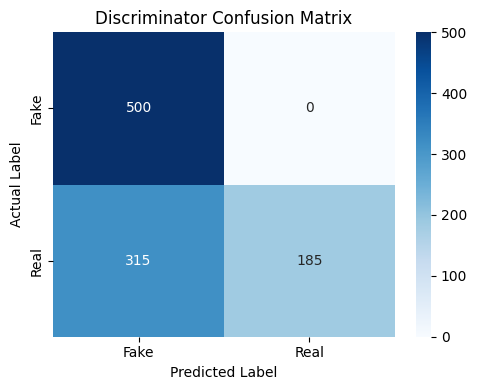


========== FINAL SUMMARY ==========
Dataset: CIFAR-10
Training subset: 2000
Image size used: 16 x 16 x 3
Architecture: DCGAN
Epochs: 3
Synthetic images generated: 16
Discriminator accuracy: 0.685
Experiment completed.


In [ ]:

# ============================================================
# FAST DCGAN: CIFAR-10 SYNTHETIC IMAGE GENERATION
# ============================================================

# 1. IMPORT LIBRARIES
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU Available:", bool(tf.config.list_physical_devices("GPU")))

# 2. LOAD CIFAR-10 DATASET
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Small subset for faster execution
x_train = x_train[:2000]
y_train = y_train[:2000]

print("\nTraining images:", len(x_train))
print("Image shape:", x_train.shape[1:])

# 3. PREPROCESSING AND EDA
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Display sample real images
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    img = np.clip((x_train[i] + 1) * 127.5, 0, 255)
    plt.imshow(img.astype("uint8"))
    plt.title(class_names[int(y_train[i][0])], fontsize=8)
    plt.axis("off")
plt.suptitle("Sample CIFAR-10 Real Images")
plt.tight_layout()
plt.show()

# Class distribution
plt.figure(figsize=(7, 3))
plt.hist(y_train.ravel(), bins=np.arange(11) - 0.5,
         edgecolor="black")
plt.xticks(range(10), class_names, rotation=40)
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

# 4. BUILD A SMALL GENERATOR
noise_dim = 64

generator = tf.keras.Sequential([
    layers.Input(shape=(noise_dim,)),
    layers.Dense(4 * 4 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Reshape((4, 4, 128)),

    layers.Conv2DTranspose(
        64, 4, strides=2, padding="same", use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(
        3, 4, strides=2, padding="same", activation="tanh"
    )
], name="Generator")

# 5. BUILD A SMALL DISCRIMINATOR
discriminator = tf.keras.Sequential([
    layers.Input(shape=(16, 16, 3)),
    layers.Conv2D(32, 3, strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.2),
    layers.Conv2D(64, 3, strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
], name="Discriminator")

# Use 16x16 images to speed up training
# Downsample real CIFAR-10 images
resize = layers.Resizing(16, 16)
real_images = resize(
    tf.convert_to_tensor(x_train)
).numpy()

# Generator must also produce 16x16 images
# Update generator output: 4x4 -> 8x8 -> 16x16
# (The architecture above produces 16x16 images.)

# 6. TRAIN DCGAN
cross_entropy = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

batch_size = 64
epochs = 3

dataset = tf.data.Dataset.from_tensor_slices(real_images)
dataset = dataset.shuffle(2000).batch(
    batch_size, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

@tf.function
def train_step(real_batch):
    n = tf.shape(real_batch)[0]

    # Train Discriminator
    noise = tf.random.normal((n, noise_dim))

    with tf.GradientTape() as d_tape:
        fake_batch = generator(noise, training=True)
        real_pred = discriminator(real_batch, training=True)
        fake_pred = discriminator(fake_batch, training=True)

        d_loss = (
            cross_entropy(tf.ones_like(real_pred) * 0.9, real_pred)
            + cross_entropy(tf.zeros_like(fake_pred), fake_pred)
        )

    d_grads = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_grads, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal((n, noise_dim))

    with tf.GradientTape() as g_tape:
        fake_batch = generator(noise, training=True)
        fake_pred = discriminator(fake_batch, training=True)
        g_loss = cross_entropy(tf.ones_like(fake_pred), fake_pred)

    g_grads = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_grads, generator.trainable_variables)
    )

    return d_loss, g_loss


d_losses, g_losses = [], []

for epoch in range(epochs):
    d_epoch, g_epoch = [], []

    for real_batch in dataset:
        d_loss, g_loss = train_step(real_batch)
        d_epoch.append(float(d_loss))
        g_epoch.append(float(g_loss))

    d_losses.append(np.mean(d_epoch))
    g_losses.append(np.mean(g_epoch))

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"D Loss: {d_losses[-1]:.4f} | "
        f"G Loss: {g_losses[-1]:.4f}"
    )

# 7. GENERATE SYNTHETIC IMAGES
noise = tf.random.normal((16, noise_dim))
fake_images = generator(noise, training=False).numpy()

plt.figure(figsize=(7, 7))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    img = np.clip((fake_images[i] + 1) * 127.5, 0, 255)
    plt.imshow(img.astype("uint8"))
    plt.axis("off")
plt.suptitle("Synthetic Images Generated by DCGAN")
plt.tight_layout()
plt.show()

# Loss graph
plt.figure(figsize=(7, 4))
plt.plot(d_losses, marker="o", label="Discriminator Loss")
plt.plot(g_losses, marker="o", label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

# 8. DISCRIMINATOR EVALUATION
# Compare 500 unseen real images and 500 generated images
n_eval = 500

real_eval = (
    x_test[:n_eval].astype("float32") - 127.5
) / 127.5
real_eval = resize(real_eval).numpy()

noise = tf.random.normal((n_eval, noise_dim))
fake_eval = generator(noise, training=False).numpy()

eval_images = np.concatenate([real_eval, fake_eval], axis=0)

# 1 = Real, 0 = Fake
y_true = np.concatenate([
    np.ones(n_eval, dtype=int),
    np.zeros(n_eval, dtype=int)
])

y_prob = discriminator.predict(eval_images, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nDiscriminator Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Discriminator Confusion Matrix")
plt.tight_layout()
plt.show()

# 9. FINAL SUMMARY
print("\n========== FINAL SUMMARY ==========")
print("Dataset: CIFAR-10")
print("Training subset:", len(x_train))
print("Image size used:", "16 x 16 x 3")
print("Architecture: DCGAN")
print("Epochs:", epochs)
print("Synthetic images generated:", len(fake_images))
print("Discriminator accuracy:",
      round(accuracy_score(y_true, y_pred), 4))
print("Experiment completed.")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training: (60000, 28, 28)
Testing : (10000, 28, 28)


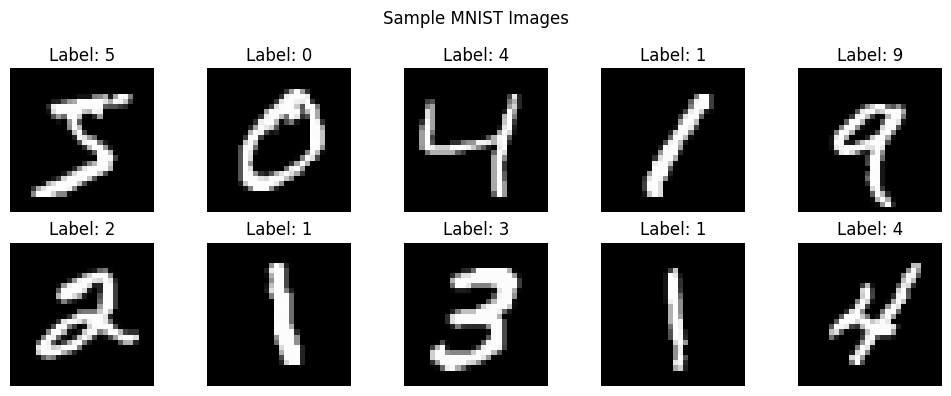

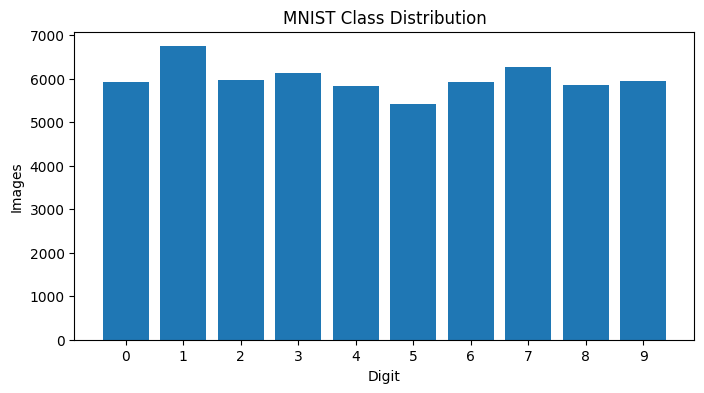

GAN Dataset: (10000, 28, 28, 1)
Pixel range: -1.0 to 1.0

Generator:


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,945 (3.28 MB)

 Trainable params: 846,273 (3.23 MB)

...

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

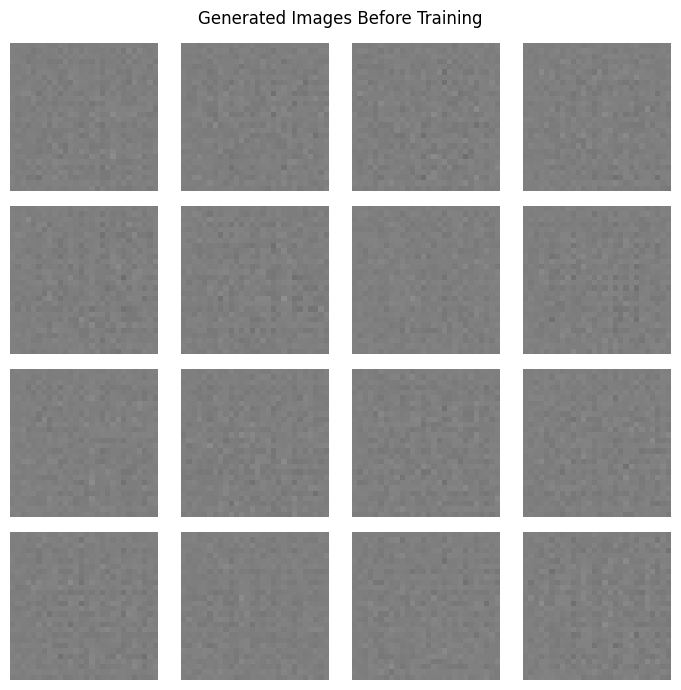

Epoch 1/15 | Generator Loss: 0.9016 | Discriminator Loss: 1.0473
Epoch 2/15 | Generator Loss: 1.0133 | Discriminator Loss: 1.0939
Epoch 3/15 | Generator Loss: 0.9839 | Discriminator Loss: 1.2151
Epoch 4/15 | Generator Loss: 0.9250 | Discriminator Loss: 1.2855
Epoch 5/15 | Generator Loss: 0.9097 | Discriminator Loss: 1.2960
Epoch 6/15 | Generator Loss: 0.9209 | Discriminator Loss: 1.2898
Epoch 7/15 | Generator Loss: 0.9135 | Discriminator Loss: 1.2826
Epoch 8/15 | Generator Loss: 0.9268 | Discriminator Loss: 1.2785
Epoch 9/15 | Generator Loss: 0.9388 | Discriminator Loss: 1.2739
Epoch 10/15 | Generator Loss: 0.9618 | Discriminator Loss: 1.2451
Epoch 11/15 | Generator Loss: 0.9890 | Discriminator Loss: 1.2253
Epoch 12/15 | Generator Loss: 1.0169 | Discriminator Loss: 1.2007
Epoch 13/15 | Generator Loss: 1.0573 | Discriminator Loss: 1.1810
Epoch 14/15 | Generator Loss: 1.0804 | Discriminator Loss: 1.1632
Epoch 15/15 | Generator Loss: 1.1172 | Discriminator Loss: 1.1349


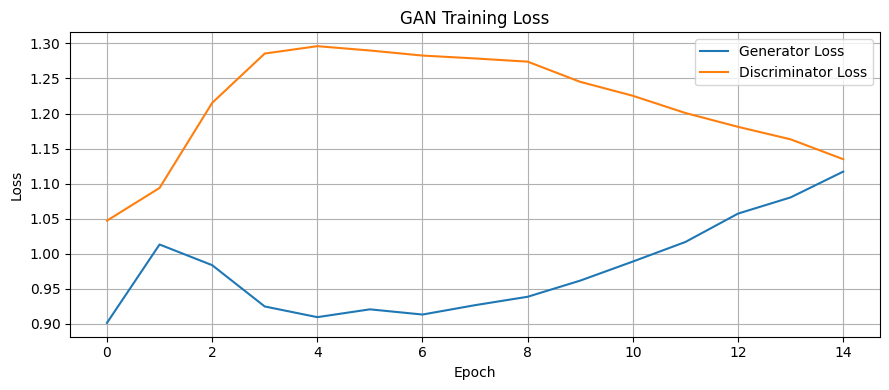

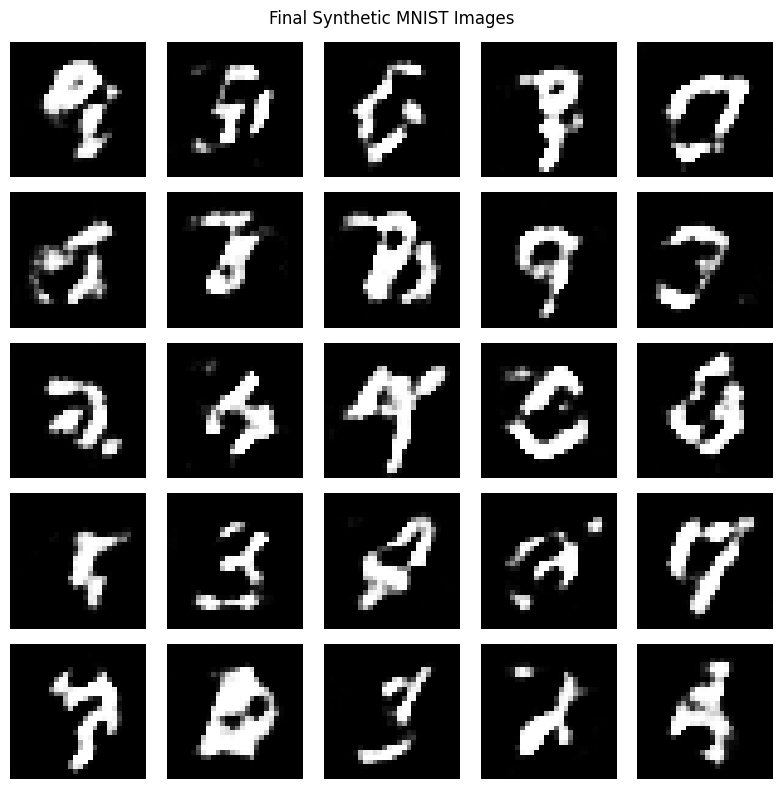

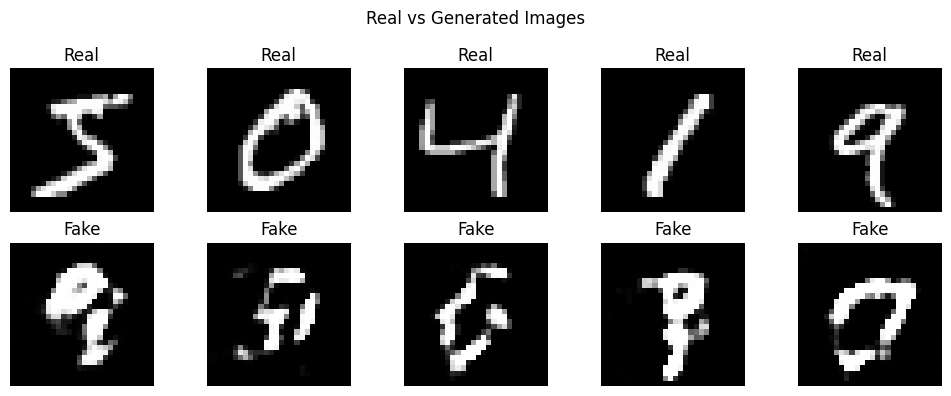

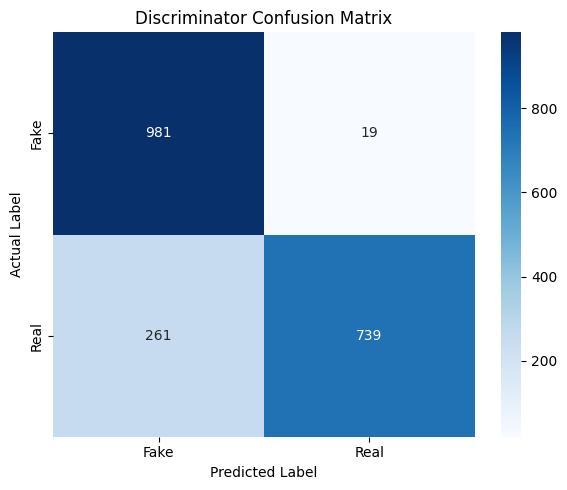


========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

        Fake       0.79      0.98      0.88      1000
        Real       0.97      0.74      0.84      1000

    accuracy                           0.86      2000
   macro avg       0.88      0.86      0.86      2000
weighted avg       0.88      0.86      0.86      2000


========== FINAL GAN SUMMARY ==========
Dataset              : MNIST
Training Images      : 10000
Image Size           : 28 x 28
Latent Dimension     : 100
Batch Size           : 128
Epochs               : 15

Discriminator Metrics:
Accuracy             : 0.8600
Precision            : 0.9749
Recall               : 0.7390
F1 Score             : 0.8407

Final Generator Loss  : 1.1172
Final Discriminator Loss: 1.1349
Synthetic Images Generated: 25

GAN experiment completed successfully!


In [ ]:

# ============================================================
# EXPERIMENT: GAN FOR SYNTHETIC IMAGE GENERATION USING MNIST
# ============================================================

# 1. IMPORT LIBRARIES, LOAD DATASET & EDA

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score,
    recall_score, f1_score
)
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training:", x_train.shape)
print("Testing :", x_test.shape)

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# Class distribution
unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(8, 4))
plt.bar(unique, counts)
plt.xlabel("Digit")
plt.ylabel("Images")
plt.title("MNIST Class Distribution")
plt.xticks(unique)
plt.show()


# 2. PREPROCESSING & DATASET PREPARATION

NUM_IMAGES = 10000
BATCH_SIZE = 128
LATENT_DIM = 100
EPOCHS = 15

# Select subset
x_train_gan = x_train[:NUM_IMAGES].astype("float32")

# Normalize pixel values to [-1, 1]
x_train_gan = (x_train_gan - 127.5) / 127.5

# Add channel dimension
x_train_gan = np.expand_dims(x_train_gan, axis=-1)

# Prepare dataset
train_dataset = tf.data.Dataset.from_tensor_slices(x_train_gan)
train_dataset = train_dataset.shuffle(NUM_IMAGES).batch(
    BATCH_SIZE, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

print("GAN Dataset:", x_train_gan.shape)
print("Pixel range:", x_train_gan.min(), "to", x_train_gan.max())


# 3. BUILD GENERATOR & DISCRIMINATOR

# Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(LATENT_DIM,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(
        64, (5, 5), strides=2,
        padding="same", use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(
        1, (5, 5), strides=2,
        padding="same", activation="tanh"
    )
], name="Generator")

# Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, (5, 5), strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Conv2D(128, (5, 5), strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
], name="Discriminator")

print("\nGenerator:")
generator.summary()

print("\nDiscriminator:")
discriminator.summary()


# 4. GENERATE INITIAL IMAGES & DEFINE GAN COMPONENTS

noise = tf.random.normal([16, LATENT_DIM])
initial_images = generator(noise, training=False)

plt.figure(figsize=(7, 7))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        initial_images[i, :, :, 0],
        cmap="gray", vmin=-1, vmax=1
    )
    plt.axis("off")

plt.suptitle("Generated Images Before Training")
plt.tight_layout()
plt.show()

# Loss functions
cross_entropy = tf.keras.losses.BinaryCrossentropy()

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output) * 0.9, real_output
    )
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )
    return real_loss + fake_loss

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)


# 5. GAN TRAINING

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(
            generated_images, training=True
        )

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(
            real_output, fake_output
        )

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


generator_losses = []
discriminator_losses = []

for epoch in range(1, EPOCHS + 1):
    gen_losses = []
    disc_losses = []

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step(image_batch)
        gen_losses.append(float(gen_loss.numpy()))
        disc_losses.append(float(disc_loss.numpy()))

    avg_gen_loss = np.mean(gen_losses)
    avg_disc_loss = np.mean(disc_losses)

    generator_losses.append(avg_gen_loss)
    discriminator_losses.append(avg_disc_loss)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f}"
    )


# 6. LOSS GRAPH & FINAL SYNTHETIC IMAGES

plt.figure(figsize=(9, 4))
plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Generate final images
noise = tf.random.normal([25, LATENT_DIM])
generated_images = generator(noise, training=False).numpy()

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray", vmin=-1, vmax=1
    )
    plt.axis("off")

plt.suptitle("Final Synthetic MNIST Images")
plt.tight_layout()
plt.show()


# 7. REAL VS FAKE IMAGE COMPARISON

plt.figure(figsize=(10, 4))

for i in range(5):
    # Real image
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_gan[i, :, :, 0], cmap="gray")
    plt.title("Real")
    plt.axis("off")

    # Generated image
    plt.subplot(2, 5, i + 6)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray", vmin=-1, vmax=1
    )
    plt.title("Fake")
    plt.axis("off")

plt.suptitle("Real vs Generated Images")
plt.tight_layout()
plt.show()


# 8. DISCRIMINATOR EVALUATION & CONFUSION MATRIX

NUM_EVAL = 1000

# Real test images
real_images = x_test[:NUM_EVAL].astype("float32")
real_images = (real_images - 127.5) / 127.5
real_images = np.expand_dims(real_images, axis=-1)

# Generated fake images
noise = tf.random.normal([NUM_EVAL, LATENT_DIM])
fake_images = generator(noise, training=False).numpy()

# Combine images: real first, fake second
evaluation_images = np.concatenate(
    [real_images, fake_images], axis=0
)

# Labels: Real = 1, Fake = 0
true_labels = np.concatenate([
    np.ones(NUM_EVAL, dtype=int),
    np.zeros(NUM_EVAL, dtype=int)
])

# Discriminator predictions
probabilities = discriminator.predict(
    evaluation_images, verbose=0
).flatten()

predicted_labels = (probabilities >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(
    true_labels, predicted_labels, labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Discriminator Confusion Matrix")
plt.tight_layout()
plt.show()


# 9. CLASSIFICATION METRICS & FINAL SUMMARY

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(
    true_labels, predicted_labels, zero_division=0
)
recall = recall_score(
    true_labels, predicted_labels, zero_division=0
)
f1 = f1_score(
    true_labels, predicted_labels, zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0
))

print("\n========== FINAL GAN SUMMARY ==========")
print("Dataset              : MNIST")
print("Training Images      :", NUM_IMAGES)
print("Image Size           : 28 x 28")
print("Latent Dimension     :", LATENT_DIM)
print("Batch Size           :", BATCH_SIZE)
print("Epochs               :", EPOCHS)

print("\nDiscriminator Metrics:")
print(f"Accuracy             : {accuracy:.4f}")
print(f"Precision            : {precision:.4f}")
print(f"Recall               : {recall:.4f}")
print(f"F1 Score             : {f1:.4f}")

print("\nFinal Generator Loss  :", round(generator_losses[-1], 4))
print("Final Discriminator Loss:", round(discriminator_losses[-1], 4))
print("Synthetic Images Generated:", len(generated_images))
print("\nGAN experiment completed successfully!")
